In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/Nassau Candy Distributor.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


## Feature engineering: lead time

- **Shipping Lead Time** = Ship Date minus Order Date, in days, as supplied (raw).
- **Adjusted Lead Time** = same gap after moving Ship Date back by whole years (hypothesis, not confirmed). Compare differences only.

In [5]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

In [6]:


# Column 1: Shipping Lead Time = Ship Date - Order Date (days, as supplied)
df["Shipping Lead Time"] = (df["Ship Date"] - df["Order Date"]).dt.days

# Column 2: Adjusted Lead Time (hypothesis, fitted to this data, not a verified business rule)
df["Order ID Year"] = df["Order ID"].str.extract(r"^[A-Z]{2}-(\d{4})-")[0].astype(int)
YEAR_SHIFT = {2021: 2, 2022: 3, 2023: 3, 2024: 4}   # years to move Ship Date back, by Order ID year
assert set(df["Order ID Year"].unique()) <= set(YEAR_SHIFT)

shifted_ship = pd.Series(
    [s - pd.DateOffset(years=YEAR_SHIFT[y]) for s, y in zip(df["Ship Date"], df["Order ID Year"])],
    index=df.index,
)
df["Adjusted Lead Time"] = (shifted_ship - df["Order Date"]).dt.days

# Checks
assert (df["Shipping Lead Time"] > 0).all()
assert (df["Adjusted Lead Time"] > 0).all()

print(df[["Shipping Lead Time", "Adjusted Lead Time"]].describe().round(2))
print("\nBy ship mode (mean):")
print(df.groupby("Ship Mode")[["Shipping Lead Time", "Adjusted Lead Time"]].mean().round(2))

       Shipping Lead Time  Adjusted Lead Time
count            10194.00            10194.00
mean              1320.84              177.59
std                262.44                1.82
min                904.00              173.00
25%               1271.00              176.00
50%               1274.00              178.00
75%               1638.00              179.00
max               1642.00              185.00

By ship mode (mean):
                Shipping Lead Time  Adjusted Lead Time
Ship Mode                                             
First Class                1338.28              175.84
Same Day                   1333.44              173.63
Second Class               1323.85              176.86
Standard Class             1314.33              178.63


In [7]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Shipping Lead Time,Order ID Year,Adjusted Lead Time
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909,2021,179
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909,2021,179
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909,2021,179
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909,2021,179
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912,2021,182


### Result: lead time columns

- Date columns converted to real dates (`datetime64`) with explicit formats.
- **Shipping Lead Time** = Ship Date minus Order Date, in days, as supplied: 904 to 1,642 days (mean about 1,320.8). Not real shipping time.
- **Adjusted Lead Time** = same gap after moving Ship Date back by whole years (2, 3, 3, 4 years for Order ID years 2021 to 2024): 173 to 185 days (mean about 177.6).
- Adjusted means sort by ship mode: Same Day (about 173.6), First Class (about 175.8), Second Class (about 176.9), Standard (about 178.6).

**Status:** The adjustment is a hypothesis fitted to this data, not a confirmed rule. Compare differences only, not exact days. Nothing is saved yet; both columns live in `df` until the final save.

In [8]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Shipping Lead Time,Order ID Year,Adjusted Lead Time
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909,2021,179
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909,2021,179
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909,2021,179
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909,2021,179
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912,2021,182


In [11]:

# Check the unique products in our dataset
print("Number of unique products:", df["Product Name"].nunique())

display(
    df[["Product Name", "Division"]]
    .drop_duplicates()
    .sort_values("Product Name")
    .reset_index(drop=True)
)


Number of unique products: 15


,Product Name,Division
0,Everlasting Gobstopper,Sugar
1,Fizzy Lifting Drinks,Sugar
2,Fun Dip,Sugar
3,Hair Toffee,Sugar
4,Kazookles,Other
5,Laffy Taffy,Sugar
6,Lickable Wallpaper,Other
7,Nerds,Sugar
8,SweeTARTS,Sugar
9,Wonka Bar - Fudge Mallows,Chocolate


In [12]:

# Map each product to its factory
product_factory_mapping = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Kazookles": "The Other Factory"
}

# Check mapping coverage before modifying df
unmapped_products = set(df["Product Name"].unique()) - set(product_factory_mapping.keys())

print("Products in dataset:", df["Product Name"].nunique())
print("Products in mapping:", len(product_factory_mapping))
print("Unmapped products:", unmapped_products)


Products in dataset: 15
Products in mapping: 15
Unmapped products: set()


In [13]:

df["Factory"] = df["Product Name"].map(product_factory_mapping)

print("Missing factory assignments:", df["Factory"].isna().sum())

print("\nOrders by factory:")
display(df["Factory"].value_counts().rename_axis("Factory").reset_index(name="Order Lines"))


Missing factory assignments: 0

Orders by factory:


,Factory,Order Lines
0,Lot's O' Nuts,5692
1,Wicked Choccy's,4152
2,Secret Factory,217
3,The Other Factory,100
4,Sugar Shack,33


In [14]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Shipping Lead Time,Order ID Year,Adjusted Lead Time,Factory
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909,2021,179,Wicked Choccy's
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909,2021,179,Wicked Choccy's
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909,2021,179,Lot's O' Nuts
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909,2021,179,Lot's O' Nuts
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912,2021,182,Wicked Choccy's


In [15]:

# Factory locations: latitude and longitude
factory_coordinates = {
    "Lot's O' Nuts": (32.881893, -111.768036),
    "Wicked Choccy's": (32.076176, -81.088371),
    "Sugar Shack": (48.119140, -96.181150),
    "Secret Factory": (41.446333, -90.565487),
    "The Other Factory": (35.117500, -89.971107)
}

# Verify all factories in the dataset have coordinates
factories_in_data = set(df["Factory"].dropna().unique())
factories_with_coordinates = set(factory_coordinates.keys())

print("Factories in dataset:", len(factories_in_data))
print("Factories with coordinates:", len(factories_with_coordinates))
print("Factories without coordinates:", factories_in_data - factories_with_coordinates)


Factories in dataset: 5
Factories with coordinates: 5
Factories without coordinates: set()


In [16]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Shipping Lead Time,Order ID Year,Adjusted Lead Time,Factory
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909,2021,179,Wicked Choccy's
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909,2021,179,Wicked Choccy's
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909,2021,179,Lot's O' Nuts
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909,2021,179,Lot's O' Nuts
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912,2021,182,Wicked Choccy's


In [17]:

df["Factory Latitude"] = df["Factory"].map(
    lambda factory: factory_coordinates[factory][0]
)

df["Factory Longitude"] = df["Factory"].map(
    lambda factory: factory_coordinates[factory][1]
)

print("Missing factory latitudes:", df["Factory Latitude"].isna().sum())
print("Missing factory longitudes:", df["Factory Longitude"].isna().sum())

display(
    df[["Product Name", "Factory", "Factory Latitude", "Factory Longitude"]]
    .drop_duplicates()
    .sort_values("Factory")
    .reset_index(drop=True)
)


Missing factory latitudes: 0
Missing factory longitudes: 0


,Product Name,Factory,Factory Latitude,Factory Longitude
0,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,32.881893,-111.768036
1,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,32.881893,-111.768036
2,Wonka Bar - Fudge Mallows,Lot's O' Nuts,32.881893,-111.768036
3,Wonka Gum,Secret Factory,41.446333,-90.565487
4,Lickable Wallpaper,Secret Factory,41.446333,-90.565487
5,Everlasting Gobstopper,Secret Factory,41.446333,-90.565487
6,Fizzy Lifting Drinks,Sugar Shack,48.119140,-96.181150
7,Laffy Taffy,Sugar Shack,48.119140,-96.181150
8,SweeTARTS,Sugar Shack,48.119140,-96.181150
9,Nerds,Sugar Shack,48.119140,-96.181150


In [18]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Sales,Units,Gross Profit,Cost,Shipping Lead Time,Order ID Year,Adjusted Lead Time,Factory,Factory Latitude,Factory Longitude
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,6.50,2,4.22,2.28,909,2021,179,Wicked Choccy's,32.076176,-81.088371
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,7.50,2,4.90,2.60,909,2021,179,Wicked Choccy's,32.076176,-81.088371
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,10.47,3,7.47,3.00,909,2021,179,Lot's O' Nuts,32.881893,-111.768036
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,10.80,3,7.50,3.30,909,2021,179,Lot's O' Nuts,32.881893,-111.768036
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,11.25,3,7.35,3.90,912,2021,182,Wicked Choccy's,32.076176,-81.088371


In [25]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost', 'Shipping Lead Time',
       'Order ID Year', 'Adjusted Lead Time', 'Factory', 'Factory Latitude',
       'Factory Longitude'],
      dtype='str')

In [26]:
df['Region'].unique()

<ArrowStringArray>
['Interior', 'Atlantic', 'Gulf', 'Pacific']
Length: 4, dtype: str

In [ ]:



factory_region_summary = (
    df.groupby(["Factory", "Region"])
    .agg(
        Unique_Orders=("Order ID", "nunique"),
        Order_Lines=("Order ID", "size")
    )
    .reset_index()
)

# Matrix: factories as rows, regions as columns
region_order_matrix = factory_region_summary.pivot(
    index="Factory",
    columns="Region",
    values="Unique_Orders"
).fillna(0).astype(int)

display(region_order_matrix)


Region,Atlantic,Gulf,Interior,Pacific
Factory,,,,
Lot's O' Nuts,1378,745,1113,1524
Secret Factory,70,35,45,63
Sugar Shack,18,4,8,3
The Other Factory,37,19,11,31
Wicked Choccy's,973,547,802,1123


## Route Categorization

To analyze distribution patterns across the supply network, routes are categorized hierarchically by **Factory → Customer Country → Customer Region → Customer State/Province**. The dataset is first divided into US and Canadian customer orders, allowing the distribution patterns in each country to be examined separately.

### 1. Factory → Customer Region

For the United States and Canada separately, orders are grouped by factory and customer region. Heatmaps visualize the number of unique orders associated with each factory-region combination, helping identify regional concentrations and understand how order volumes are distributed across the regions served by each factory.

### 2. Factory → Customer State/Province

Within each country, the analysis is further refined from region to individual state or province. Orders are grouped by factory, customer region, and state/province to identify specific destinations receiving the most orders and compare distribution patterns at a more granular geographic level.

This hierarchical approach provides a structured view of the distribution network, moving from country-level separation to regional analysis and finally to state/province-level detail.

In [27]:

# Level 1: Factory → Country

factory_country_summary = (
    df.groupby(["Factory", "Country/Region"])
    .agg(
        Unique_Orders=("Order ID", "nunique"),
        Order_Lines=("Order ID", "size")
    )
    .reset_index()
    .sort_values(["Factory", "Country/Region"])
)

display(factory_country_summary)


,Factory,Country/Region,Unique_Orders,Order_Lines
0,Lot's O' Nuts,Canada,91,104
1,Lot's O' Nuts,United States,4669,5588
2,Secret Factory,Canada,4,4
3,Secret Factory,United States,209,213
4,Sugar Shack,United States,33,33
5,The Other Factory,United States,98,100
6,Wicked Choccy's,Canada,65,92
7,Wicked Choccy's,United States,3380,4060


In [28]:
# Separate US and Canadian customer orders
df_us = df[
    df["Country/Region"].isin(["United States", "United States of America", "US"])
].copy()

df_canada = df[
    df["Country/Region"].isin(["Canada"])
].copy()

print("US records:", len(df_us))
print("Canada records:", len(df_canada))
print("Total records:", len(df))

# Verify that no records were excluded
assert len(df_us) + len(df_canada) == len(df), "Check country names!"

US records: 9994
Canada records: 200
Total records: 10194


In [33]:
df_canada['Region'].unique()

<ArrowStringArray>
['Atlantic', 'Pacific', 'Interior']
Length: 3, dtype: str

In [32]:
df_us['Region'].unique()

<ArrowStringArray>
['Interior', 'Atlantic', 'Gulf', 'Pacific']
Length: 4, dtype: str

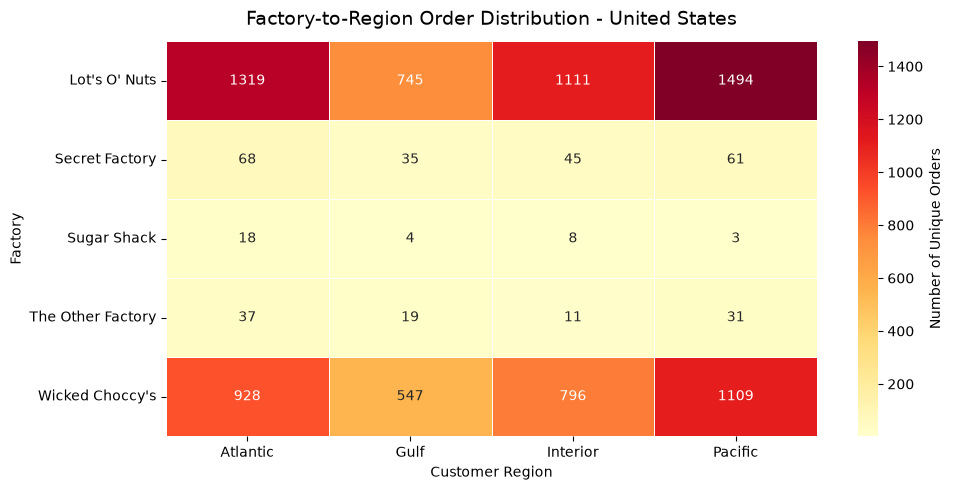

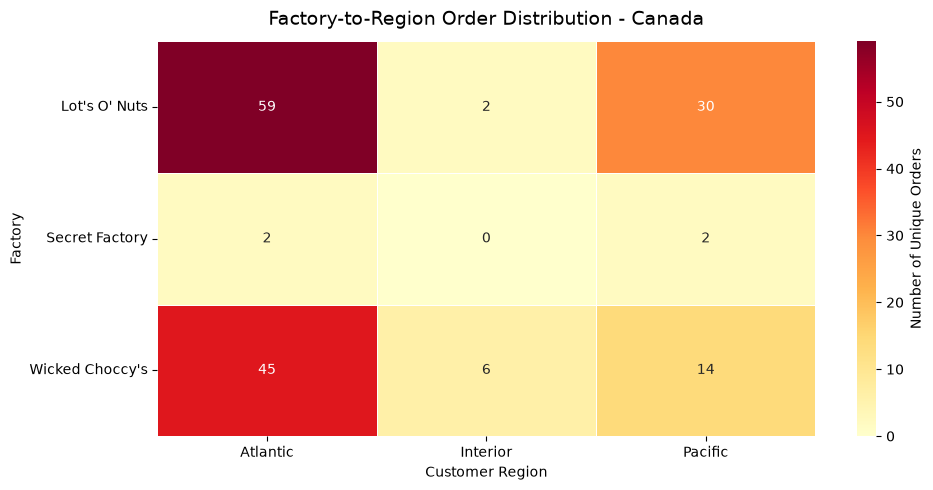

In [30]:

import matplotlib.pyplot as plt
import seaborn as sns

def plot_factory_region_heatmap(data, country):
    # Count unique orders for each factory-region combination
    region_matrix = (
        data.groupby(["Factory", "Region"])["Order ID"]
        .nunique()
        .unstack(fill_value=0)
    )

    # Plot heatmap
    plt.figure(figsize=(10, 5))

    sns.heatmap(
        region_matrix,
        annot=True,
        fmt="d",
        cmap="YlOrRd",
        linewidths=0.5,
        cbar_kws={"label": "Number of Unique Orders"}
    )

    plt.title(
        f"Factory-to-Region Order Distribution - {country}",
        fontsize=14,
        pad=12
    )
    plt.xlabel("Customer Region")
    plt.ylabel("Factory")
    plt.xticks(rotation=0)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


# Generate the two heatmaps
plot_factory_region_heatmap(df_us, "United States")
plot_factory_region_heatmap(df_canada, "Canada")


In [35]:

# Level 3: Factory → Country → Region → State/Province

factory_state_summary = (
    df.groupby(
        ["Country/Region", "Region", "State/Province", "Factory"],
        dropna=False
    )
    .agg(
        Unique_Orders=("Order ID", "nunique"),
        Order_Lines=("Order ID", "size")
    )
    .reset_index()
    .sort_values(
        ["Country/Region", "Region", "State/Province", "Factory"]
    )
)

display(factory_state_summary.head(30))


,Country/Region,Region,State/Province,Factory,Unique_Orders,Order_Lines
0,Canada,Atlantic,New Brunswick,Lot's O' Nuts,4,4
1,Canada,Atlantic,New Brunswick,Wicked Choccy's,4,4
2,Canada,Atlantic,Newfoundland and Labrador,Lot's O' Nuts,5,6
3,Canada,Atlantic,Nova Scotia,Wicked Choccy's,6,6
4,Canada,Atlantic,Ontario,Lot's O' Nuts,24,28
5,Canada,Atlantic,Ontario,Wicked Choccy's,17,30
6,Canada,Atlantic,Prince Edward Island,Lot's O' Nuts,6,6
7,Canada,Atlantic,Prince Edward Island,Wicked Choccy's,2,4
8,Canada,Atlantic,Quebec,Lot's O' Nuts,20,24
9,Canada,Atlantic,Quebec,Secret Factory,2,2


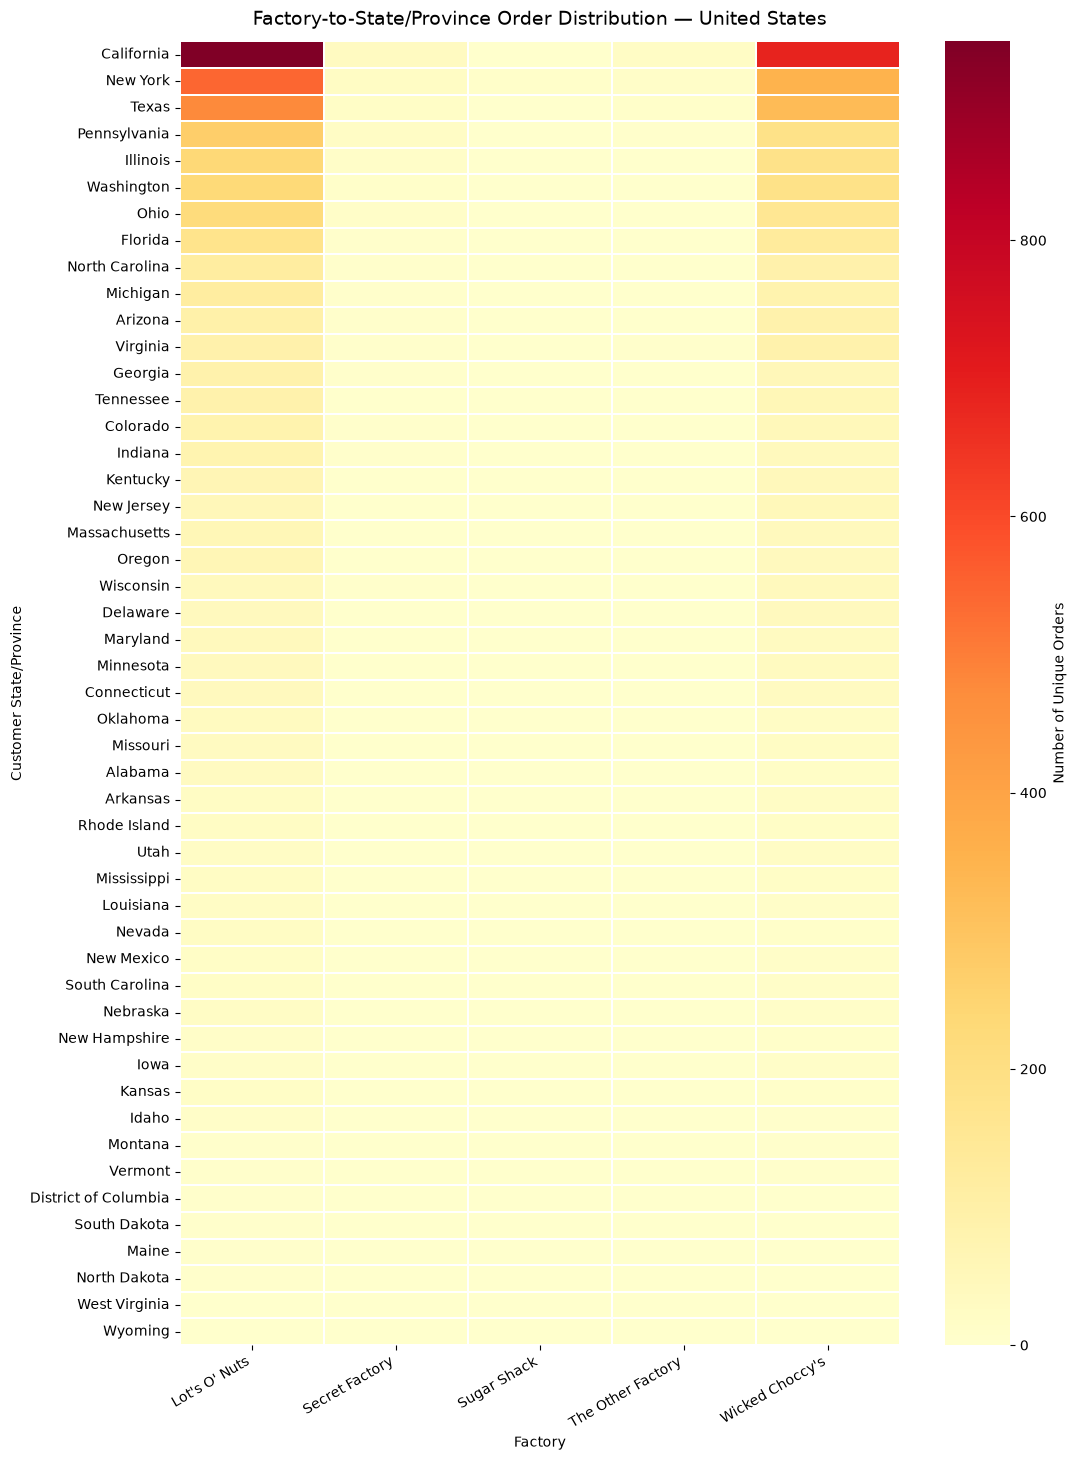

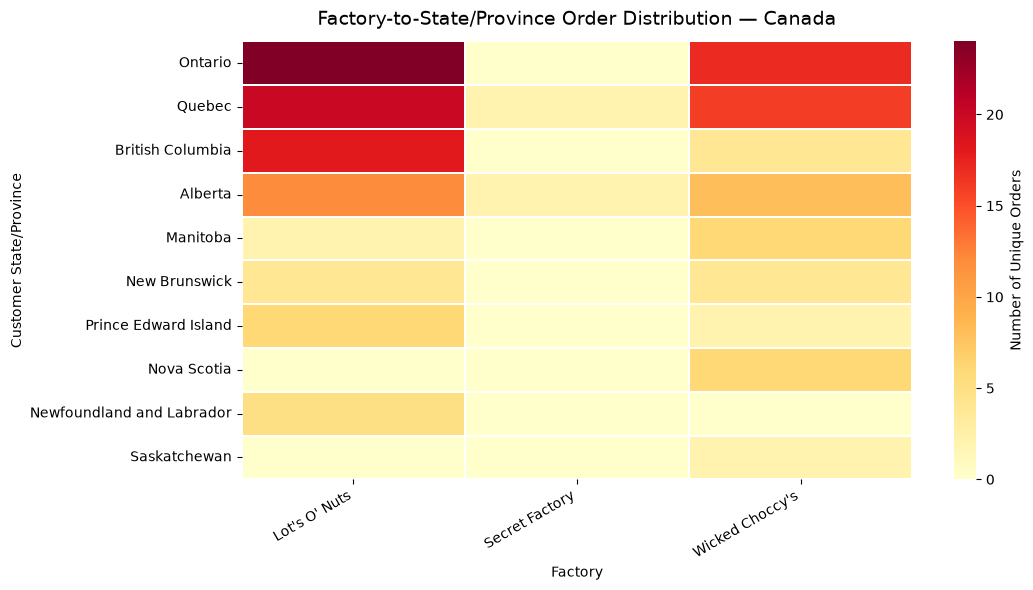

In [36]:

import matplotlib.pyplot as plt
import seaborn as sns

def plot_factory_state_heatmap(data, country):
    # Count unique orders by state/province and factory
    state_matrix = (
        data.groupby(["State/Province", "Factory"])["Order ID"]
        .nunique()
        .unstack(fill_value=0)
    )

    # Sort destinations by total order count
    state_matrix = state_matrix.loc[
        state_matrix.sum(axis=1).sort_values(ascending=False).index
    ]

    plt.figure(figsize=(11, max(6, len(state_matrix) * 0.3)))

    sns.heatmap(
        state_matrix,
        cmap="YlOrRd",
        annot=False,
        linewidths=0.3,
        cbar_kws={"label": "Number of Unique Orders"}
    )

    plt.title(
        f"Factory-to-State/Province Order Distribution — {country}",
        fontsize=14,
        pad=12
    )
    plt.xlabel("Factory")
    plt.ylabel("Customer State/Province")
    plt.xticks(rotation=30, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


# Generate state/province heatmaps
plot_factory_state_heatmap(df_us, "United States")
plot_factory_state_heatmap(df_canada, "Canada")


In [37]:

# Group shipment records by shipping mode
ship_mode_summary = (
    df.groupby("Ship Mode")
    .agg(
        Order_Lines=("Order ID", "size"),
        Unique_Orders=("Order ID", "nunique"),
        Average_Lead_Time=("Shipping Lead Time", "mean"),
        Median_Lead_Time=("Shipping Lead Time", "median")
    )
    .reset_index()
    .sort_values("Unique_Orders", ascending=False)
)

display(ship_mode_summary.round(2))


,Ship Mode,Order_Lines,Unique_Orders,Average_Lead_Time,Median_Lead_Time
3,Standard Class,6120,5142,1314.33,1274.0
2,Second Class,1979,1653,1323.85,1273.0
0,First Class,1548,1312,1338.28,1272.0
1,Same Day,547,442,1333.44,1269.0


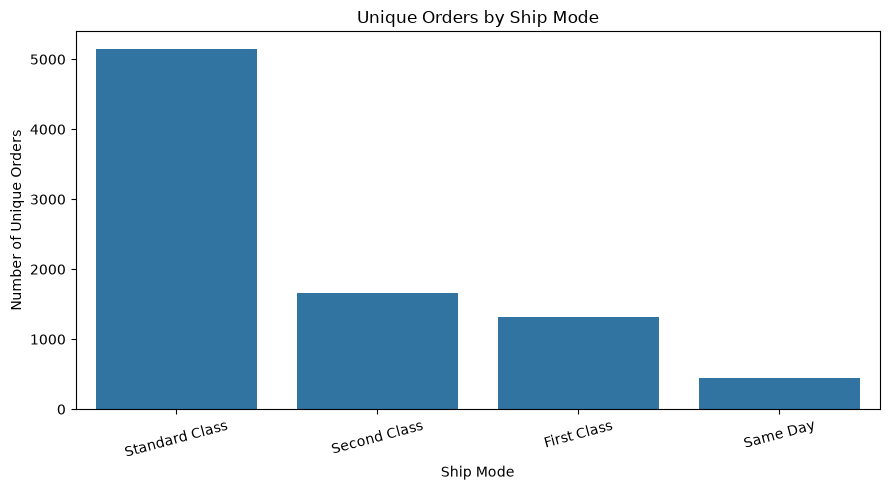

In [38]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=ship_mode_summary,
    x="Ship Mode",
    y="Unique_Orders"
)

plt.title("Unique Orders by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Number of Unique Orders")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [40]:
df.to_csv("../data/processed/orders_prepared.csv", index=False)
print("Prepared dataset saved successfully.")

Prepared dataset saved successfully.
